<div dir="rtl">

# הרצאה 6: אינפלציה

**מה במחברת.** פותרים את משוואת התנועה של האינפלטון בדיוק (בלי קירוב slow roll), סופרים e-folds, ומשווים את התחזיות $(n_s, r)$ של כמה פוטנציאלים למגבלות של Planck ו-BICEP/Keck.

יחידות: $M_{\rm Pl}=(8\pi G)^{-1/2}=1$.
$$\ddot\phi+3H\dot\phi+V'(\phi)=0,\qquad H^2=\frac13\Big(\tfrac12\dot\phi^2+V\Big),\qquad
\epsilon_V=\frac12\Big(\frac{V'}{V}\Big)^2,\quad \eta_V=\frac{V''}{V},$$
$$n_s\simeq1-6\epsilon_V+2\eta_V,\qquad r\simeq16\epsilon_V,\qquad N=\int_{\phi_{\rm end}}^{\phi_*}\frac{d\phi}{\sqrt{2\epsilon_V}} .$$

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad, solve_ivp
from scipy.optimize import brentq, minimize_scalar

plt.rcParams.update({"font.size": 12, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
c = 299792.458            # km/s

<div dir="rtl">

## 1. פתרון מדויק ל-$V=\tfrac12m^2\phi^2$
משתמשים ב-$N=\ln a$ כמשתנה זמן. אינפלציה נגמרת כש-$\epsilon_H\equiv-\dot H/H^2=\tfrac12(d\phi/dN)^2$ מגיע ל-1.

</div>

total e-folds from phi=16: N = 64.56   (slow roll: (16^2 - 2)/4 = 63.50)
phi at the end of inflation: 1.009   (slow roll: sqrt(2) = 1.414)


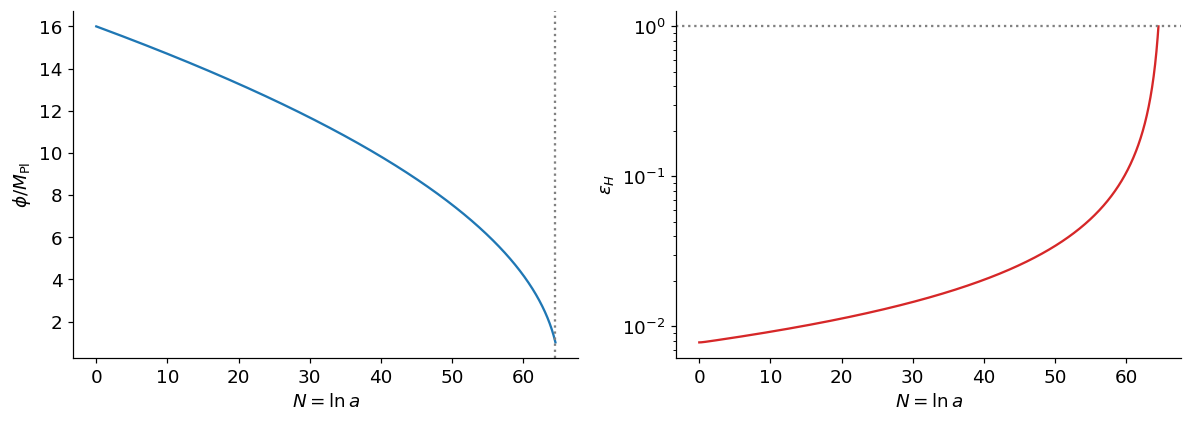

In [2]:
def evolve(V, dV, phi0, N_max=100):
    # phi'' (in N) from the exact equations; y = [phi, dphi/dN]
    def rhs(N, y):
        phi, p = y
        H2 = V(phi)/(3 - 0.5*p**2)
        eps = 0.5*p**2
        return [p, -(3 - eps)*p - dV(phi)/H2]
    end = lambda N, y: 0.5*y[1]**2 - 1; end.terminal = True; end.direction = 1
    # slow-roll initial velocity
    p0 = -dV(phi0)/V(phi0)
    s = solve_ivp(rhs, [0, N_max], [phi0, p0], events=end, rtol=1e-10, atol=1e-12, dense_output=True, max_step=0.05)
    return s

m = 1.0
V = lambda f: 0.5*m**2*f**2; dV = lambda f: m**2*f
s = evolve(V, dV, phi0=16.0)
N_end = s.t_events[0][0]
print(f"total e-folds from phi=16: N = {N_end:.2f}   (slow roll: (16^2 - 2)/4 = {(16**2 - 2)/4:.2f})")
print(f"phi at the end of inflation: {s.y_events[0][0][0]:.3f}   (slow roll: sqrt(2) = {np.sqrt(2):.3f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(s.t, s.y[0], "C0"); ax[0].axvline(N_end, color="gray", ls=":")
ax[0].set_xlabel(r"$N=\ln a$"); ax[0].set_ylabel(r"$\phi/M_{\rm Pl}$")
ax[1].semilogy(s.t, 0.5*s.y[1]**2, "C3"); ax[1].axhline(1, color="gray", ls=":")
ax[1].set_xlabel(r"$N=\ln a$"); ax[1].set_ylabel(r"$\epsilon_H$")
fig.tight_layout(); plt.show()

<div dir="rtl">

**שימו לב.** slow roll מנבא את מספר ה-e-folds בטעות של e-fold אחד בלבד (64.6 מול 63.5). את $\phi_{\rm end}$ הוא מנבא גרוע יותר (1.0 מול 1.41), כי בסוף האינפלציה $\epsilon$ כבר לא קטן והקירוב נשבר.

## 2. תחזיות $(n_s,r)$
מחשבים נומרית את $\epsilon_V,\eta_V$ בנקודה $\phi_*$ שבה נשארו $N_*$ e-folds עד הסוף, עבור $N_*=50$ ו-$60$.

</div>

In [3]:
def predictions(V, dV, d2V, phi_end_guess, N_star, phi_hi):
    eps = lambda f: 0.5*(dV(f)/V(f))**2
    phi_end = brentq(lambda f: eps(f) - 1, *phi_end_guess)
    N_of = lambda f: quad(lambda x: V(x)/dV(x), phi_end, f)[0]
    phi_s = brentq(lambda f: N_of(f) - N_star, phi_end + 1e-6, phi_hi)
    e, n = eps(phi_s), d2V(phi_s)/V(phi_s)
    return 1 - 6*e + 2*n, 16*e

al = np.sqrt(2/3)
potentials = {
    r"$\phi^2$":        (lambda f: f**2, lambda f: 2*f, lambda f: 2 + 0*f, (0.5, 3), 30),
    r"$\phi^{2/3}$":    (lambda f: f**(2/3), lambda f: (2/3)*f**(-1/3), lambda f: -(2/9)*f**(-4/3), (0.1, 2), 30),
    "Starobinsky":      (lambda f: (1 - np.exp(-al*f))**2, lambda f: 2*al*np.exp(-al*f)*(1 - np.exp(-al*f)),
                         lambda f: 2*al**2*np.exp(-al*f)*(2*np.exp(-al*f) - 1), (0.3, 3), 15),
    r"$\phi^4$":        (lambda f: f**4, lambda f: 4*f**3, lambda f: 12*f**2, (1, 5), 40),
}
res = {}
for name, (V_, dV_, d2V_, rng_, hi) in potentials.items():
    res[name] = [predictions(V_, dV_, d2V_, rng_, Ns, hi) for Ns in (50, 60)]
    for Ns, (ns, r) in zip((50, 60), res[name]):
        print(f"{name:14s} N*={Ns}:  n_s = {ns:.4f},  r = {r:.4f}")

$\phi^2$       N*=50:  n_s = 0.9604,  r = 0.1584
$\phi^2$       N*=60:  n_s = 0.9669,  r = 0.1322
$\phi^{2/3}$   N*=50:  n_s = 0.9734,  r = 0.0532
$\phi^{2/3}$   N*=60:  n_s = 0.9778,  r = 0.0443
Starobinsky    N*=50:  n_s = 0.9616,  r = 0.0042
Starobinsky    N*=60:  n_s = 0.9678,  r = 0.0030
$\phi^4$       N*=50:  n_s = 0.9412,  r = 0.3137
$\phi^4$       N*=60:  n_s = 0.9508,  r = 0.2623


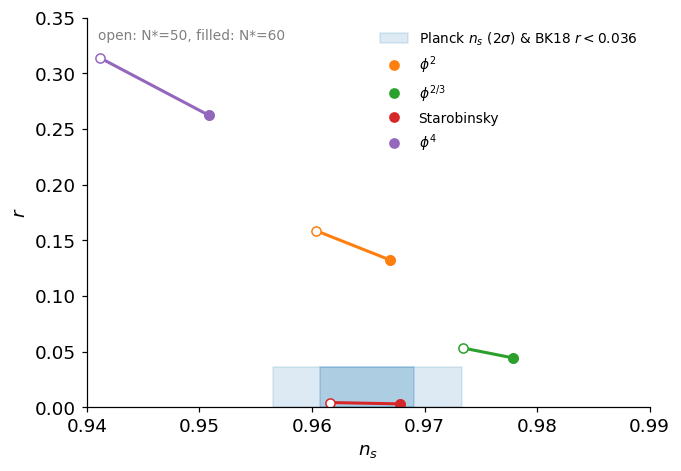

In [4]:
fig, ax = plt.subplots(figsize=(6.6, 4.6))
# Planck 2018 n_s = 0.9649 +- 0.0042 ; BICEP/Keck 2021: r_0.05 < 0.036 (95%)
ax.axvspan(0.9649 - 2*0.0042, 0.9649 + 2*0.0042, ymax=0.036/0.35, color="C0", alpha=0.15, label=r"Planck $n_s$ (2$\sigma$) & BK18 $r<0.036$")
ax.axvspan(0.9649 - 0.0042, 0.9649 + 0.0042, ymax=0.036/0.35, color="C0", alpha=0.25)
for i, (name, pts) in enumerate(res.items()):
    (n1, r1), (n2, r2) = pts
    ax.plot([n1, n2], [r1, r2], "-", color=f"C{i+1}", lw=2)
    ax.plot([n1, n2], [r1, r2], "o", color=f"C{i+1}", ms=6, mfc="white")
    ax.plot(n2, r2, "o", color=f"C{i+1}", ms=6, label=name)
ax.set_xlim(0.94, 0.99); ax.set_ylim(0, 0.35)
ax.set_xlabel(r"$n_s$"); ax.set_ylabel(r"$r$"); ax.legend(frameon=False, fontsize=9)
ax.text(0.941, 0.33, "open: N*=50, filled: N*=60", fontsize=9, color="gray"); plt.show()

<div dir="rtl">

**מה רואים.** $\phi^4$ ו-$\phi^2$ נפסלים בגלל $r$ גדול מדי. Starobinsky ($n_s\simeq1-2/N$, $r\simeq12/N^2$) יושב בתוך האזור המותר.
המגבלות: Planck 2018 X (A&A 641, A10, 2020); BICEP/Keck (PRL 127, 151301, 2021).

---
# תרגילים פתורים נוספים

### תרגיל א: Starobinsky אנליטית
בגבול $\phi\gg1$: $\epsilon_V\simeq\tfrac43e^{-2\alpha\phi}$, $\eta_V\simeq-\tfrac43e^{-\alpha\phi}$ עם $\alpha=\sqrt{2/3}$, ו-$N\simeq\tfrac34e^{\alpha\phi}$. לכן $n_s\simeq1-2/N$, $r\simeq12/N^2$. השוו לתוצאה הנומרית.

</div>

In [5]:
for Ns, (ns, r) in zip((50, 60), res["Starobinsky"]):
    print(f"N*={Ns}: numeric n_s={ns:.4f}, r={r:.5f}   |   1-2/N = {1 - 2/Ns:.4f},  12/N^2 = {12/Ns**2:.5f}")

N*=50: numeric n_s=0.9616, r=0.00419   |   1-2/N = 0.9600,  12/N^2 = 0.00480
N*=60: numeric n_s=0.9678, r=0.00296   |   1-2/N = 0.9667,  12/N^2 = 0.00333


<div dir="rtl">

### תרגיל ב: סקאלת האנרגיה של האינפלציה
האמפליטודה של ההפרעות הסקלריות $A_s=\frac{V}{24\pi^2\epsilon_V M_{\rm Pl}^4}=2.1\times10^{-9}$ ו-$r=16\epsilon_V$ נותנים
$V^{1/4}=\big(\tfrac{3\pi^2}{2}A_sr\big)^{1/4}M_{\rm Pl}$. חשבו עבור $r=0.036$ ו-$r=0.003$ (Starobinsky).

</div>

In [6]:
MPl_GeV = 2.435e18; As = 2.1e-9
for r in (0.036, 0.0035):
    print(f"r = {r}:  V^1/4 = {(1.5*np.pi**2*As*r)**0.25*MPl_GeV:.2e} GeV,  H_inf = {np.sqrt(1.5*np.pi**2*As*r/3)*MPl_GeV:.2e} GeV")

r = 0.036:  V^1/4 = 1.41e+16 GeV,  H_inf = 4.70e+13 GeV
r = 0.0035:  V^1/4 = 7.86e+15 GeV,  H_inf = 1.47e+13 GeV


<div dir="rtl">

**מסקנה.** אינפלציה עם $r$ שאפשר למדוד מתרחשת בסקאלת GUT ($\sim10^{16}\,$GeV), טריליון פעמים מעל אנרגיות ה-LHC.

### תרגיל ג: גודל האינפלטון במסה $m$
ל-$\phi^2$ עם $N_*=60$: מה $m$ שנדרש כדי לקבל את $A_s$ הנמדד? (רמז: $A_s=\frac{V}{24\pi^2\epsilon_V}$ עם $\phi_*^2=4N_*+2$.)

</div>

In [7]:
Ns = 60; phi_s2 = 4*Ns + 2
eps_s = 2/phi_s2
m2 = As*24*np.pi**2*eps_s/(0.5*phi_s2)
print(f"phi_* = {np.sqrt(phi_s2):.2f} M_Pl,  m = {np.sqrt(m2):.2e} M_Pl = {np.sqrt(m2)*MPl_GeV:.2e} GeV")

phi_* = 15.56 M_Pl,  m = 5.83e-06 M_Pl = 1.42e+13 GeV
